# 1.Buisness Understanding

## 2.Load and EDA

In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

In [3]:
df = pd.read_csv('Telco-Customer-Churn.csv')
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


(7043, 21)

In [5]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

identifier_columns = [
    col for col in df.columns
    if col.lower().endswith('id')
]

categorical_columns = [
    col for col in df.select_dtypes(include=['object', 'category', 'bool']).columns
    if col not in identifier_columns
]

# Treat binary indicators as categorical rather than continuous numeric features.
categorical_columns += [
    col for col in df.select_dtypes(include='number').columns
    if col not in identifier_columns and df[col].nunique(dropna=True) <= 2
]

numerical_columns = [
    col for col in df.select_dtypes(include='number').columns
    if col not in identifier_columns and col not in categorical_columns
]

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)
print("Identifier columns:", identifier_columns)

Numerical columns: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'Churn', 'SeniorCitizen']
Identifier columns: ['customerID']


In [6]:
# Data types
print("Data types:")
display(df.dtypes.to_frame("Data type"))

# Missing values
missing = df.isna().sum()
missing_summary = pd.DataFrame({
    "Missing values": missing,
    "Missing (%)": (missing / len(df) * 100).round(2)
})
print("Missing values:")
display(missing_summary[missing_summary["Missing values"] > 0])

# Duplicate rows
print(f"Duplicate rows: {df.duplicated().sum()}")

# Target distribution
print("Churn distribution:")
display(pd.DataFrame({
    "Count": df["Churn"].value_counts(),
    "Percentage": (df["Churn"].value_counts(normalize=True) * 100).round(2)
}))

Data types:


,Data type
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


Missing values:


,Missing values,Missing (%)
TotalCharges,11,0.16


Duplicate rows: 0
Churn distribution:


,Count,Percentage
Churn,,
No,5174,73.46
Yes,1869,26.54


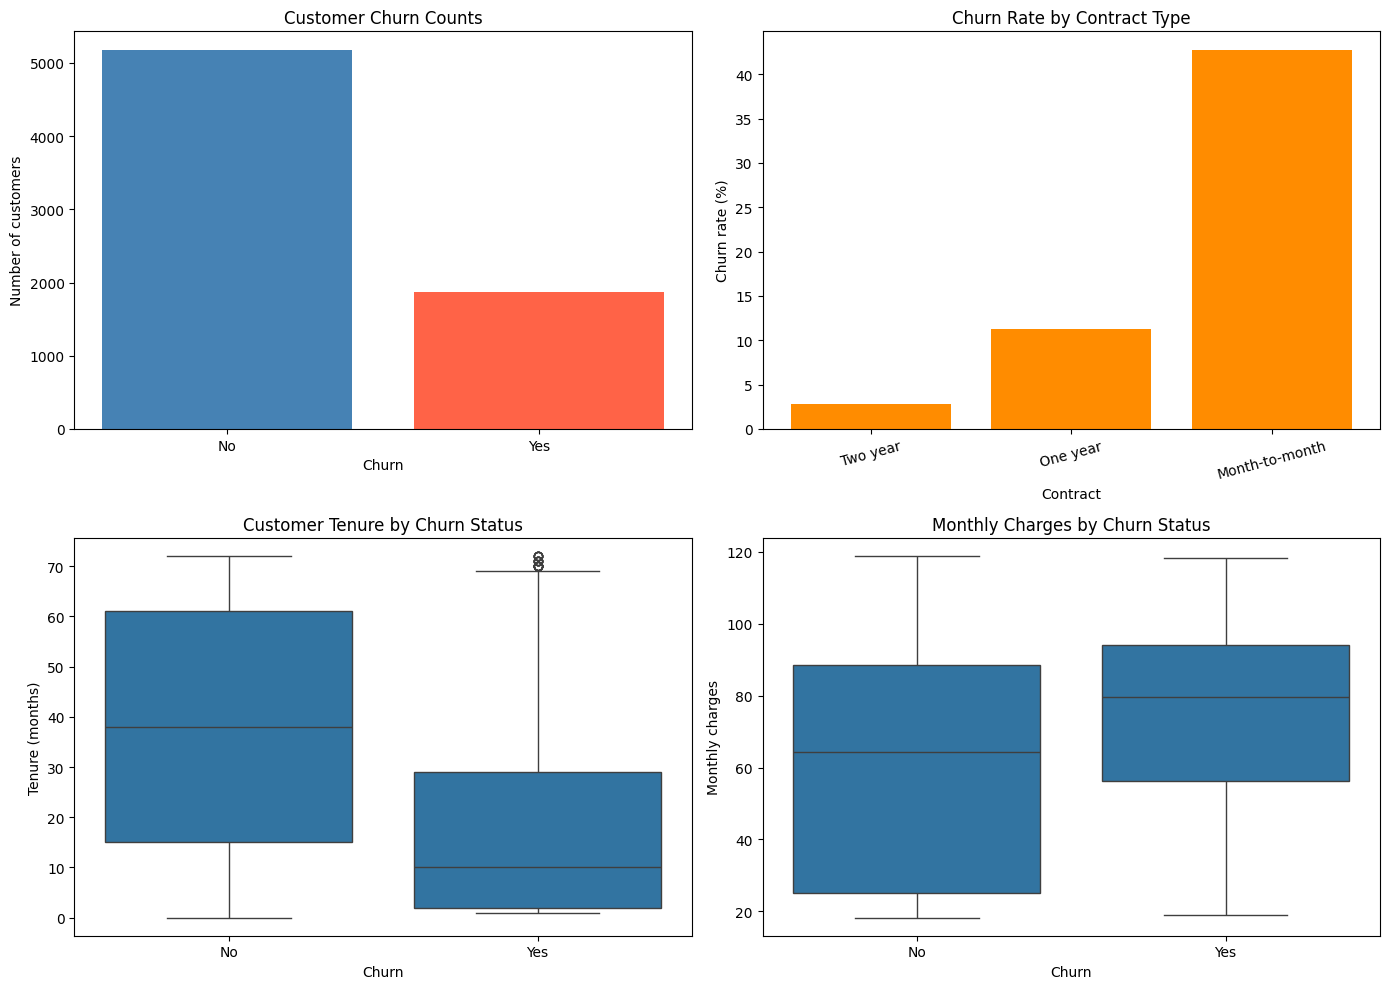

In [7]:
# Churn distribution and relationships with key customer attributes
eda_df = df.copy()
eda_df["ChurnFlag"] = eda_df["Churn"].map({"No": 0, "Yes": 1})

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Overall churn counts
churn_counts = eda_df["Churn"].value_counts().reindex(["No", "Yes"])
axes[0, 0].bar(churn_counts.index, churn_counts.values, color=["steelblue", "tomato"])
axes[0, 0].set(title="Customer Churn Counts", xlabel="Churn", ylabel="Number of customers")

# 2. Churn rate by contract type
contract_churn = (
    eda_df.groupby("Contract", observed=False)["ChurnFlag"]
    .mean()
    .mul(100)
    .sort_values()
)
axes[0, 1].bar(contract_churn.index, contract_churn.values, color="darkorange")
axes[0, 1].set(title="Churn Rate by Contract Type", xlabel="Contract", ylabel="Churn rate (%)")
axes[0, 1].tick_params(axis="x", rotation=15)

# 3. Tenure by churn status
sns.boxplot(data=eda_df, x="Churn", y="tenure", order=["No", "Yes"], ax=axes[1, 0])
axes[1, 0].set(title="Customer Tenure by Churn Status", xlabel="Churn", ylabel="Tenure (months)")

# 4. Monthly charges by churn status
sns.boxplot(data=eda_df, x="Churn", y="MonthlyCharges", order=["No", "Yes"], ax=axes[1, 1])
axes[1, 1].set(title="Monthly Charges by Churn Status", xlabel="Churn", ylabel="Monthly charges")

plt.tight_layout()
plt.show()

### EDA chart interpretations

**1. Customer Churn Counts**  
Most customers stay: about **5,174 (73.5%)** did not churn and **1,869 (26.5%)** did. The target is imbalanced, so a model that always predicts “No” would look accurate but would miss the customers we care about. Later steps should use metrics such as recall, precision, F1, or ROC-AUC rather than accuracy alone, and may need class-weighting or resampling.

**2. Churn Rate by Contract Type**  
Contract length is strongly tied to churn. **Month-to-month** customers leave at about **43%**, versus **11%** on one-year contracts and only **3%** on two-year contracts. Flexible plans are easier to cancel, so this group is the highest-risk segment and a natural place for retention offers. Contract type should be a key predictor in the model.

**3. Customer Tenure by Churn Status**  
Customers who churn tend to be newer. Median tenure is about **10 months** for churners versus **38 months** for those who stay; many churners leave in the first few months (25th percentile is 2 months). Risk is concentrated early in the relationship, so onboarding and first-year engagement matter more than late-stage retention.

**4. Monthly Charges by Churn Status**  
Churners pay more on average: median monthly charges are about **$80** versus **$64** for retained customers, and the lower half of the churn group still starts around **$56**. Higher bills (often fiber or add-on packages) line up with higher exit risk. Combined with the tenure plot, the highest-risk profile is a **new, high-paying, month-to-month** customer.

## 3. Data preprocessing and splitting

We drop the customer ID, encode the target, then **split before fitting** any transformers so test data does not leak into preprocessing. Missing `TotalCharges` values belong to customers with `tenure = 0` (not billed yet), so they are filled with 0. Numeric features are scaled; categoricals are one-hot encoded.

In [8]:
# Drop identifier and separate features from the target
model_df = df.drop(columns=identifier_columns).copy()
model_df["Churn"] = model_df["Churn"].map({"No": 0, "Yes": 1})

X = model_df.drop(columns=["Churn"])
y = model_df["Churn"]

feature_categorical = [col for col in categorical_columns if col != "Churn"]
feature_numerical = numerical_columns.copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

print(f"Training set: {X_train.shape[0]} rows ({y_train.mean() * 100:.2f}% churn)")
print(f"Test set:     {X_test.shape[0]} rows ({y_test.mean() * 100:.2f}% churn)")

Training set: 5634 rows (26.54% churn)
Test set:     1409 rows (26.54% churn)


In [9]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value=0)),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, feature_numerical),
        ("categorical", categorical_pipeline, feature_categorical),
    ]
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

encoded_feature_names = preprocessor.get_feature_names_out()
X_train_processed = pd.DataFrame(X_train_processed, columns=encoded_feature_names, index=X_train.index)
X_test_processed = pd.DataFrame(X_test_processed, columns=encoded_feature_names, index=X_test.index)

print(f"Processed training features: {X_train_processed.shape}")
print(f"Processed test features:     {X_test_processed.shape}")
print(f"Number of encoded features:  {len(encoded_feature_names)}")
X_train_processed.head()

Processed training features: (5634, 46)
Processed test features:     (1409, 46)
Number of encoded features:  46


,numeric__tenure,numeric__MonthlyCharges,numeric__TotalCharges,categorical__gender_Female,categorical__gender_Male,categorical__Partner_No,categorical__Partner_Yes,categorical__Dependents_No,categorical__Dependents_Yes,categorical__PhoneService_No,...,categorical__Contract_One year,categorical__Contract_Two year,categorical__PaperlessBilling_No,categorical__PaperlessBilling_Yes,categorical__PaymentMethod_Bank transfer (automatic),categorical__PaymentMethod_Credit card (automatic),categorical__PaymentMethod_Electronic check,categorical__PaymentMethod_Mailed check,categorical__SeniorCitizen_0,categorical__SeniorCitizen_1
3738,0.102371,-0.521976,-0.262257,0.0,1.0,1.0,0.0,1.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
3151,-0.711743,0.337478,-0.503635,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
4860,-0.793155,-0.809013,-0.749883,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
3867,-0.263980,0.284384,-0.172722,1.0,0.0,0.0,1.0,1.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
3810,-1.281624,-0.676279,-0.989374,0.0,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


## 4. Baseline and model comparison

All models use the **same stratified train/test split** (`X_train` / `X_test`) and the **same preprocessing steps** inside a `Pipeline`, so differences come from the algorithm, not from different data. Logistic Regression is the baseline. Decision Tree, Random Forest, and KNN are trained next.

In [13]:
def make_model_pipeline(classifier):
    """Reuse the same preprocessing on the original train/test columns."""
    return Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", classifier),
    ])

models = {
    "Logistic Regression (baseline)": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN": KNeighborsClassifier(),
}

results = []
predictions = {}

for name, classifier in models.items():
    pipe = make_model_pipeline(classifier)
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=1),
        "Recall": recall_score(y_test, y_pred, pos_label=1),
        "F1-score": f1_score(y_test, y_pred, pos_label=1),
    })

results_df = pd.DataFrame(results).set_index("Model")
display(results_df.round(4))

,Accuracy,Precision,Recall,F1-score
Model,,,,
Logistic Regression (baseline),0.8055,0.6572,0.5588,0.6040
Decision Tree,0.7225,0.4777,0.4866,0.4821
Random Forest,0.7885,0.6310,0.4893,0.5512
KNN,0.7573,0.5419,0.5535,0.5476


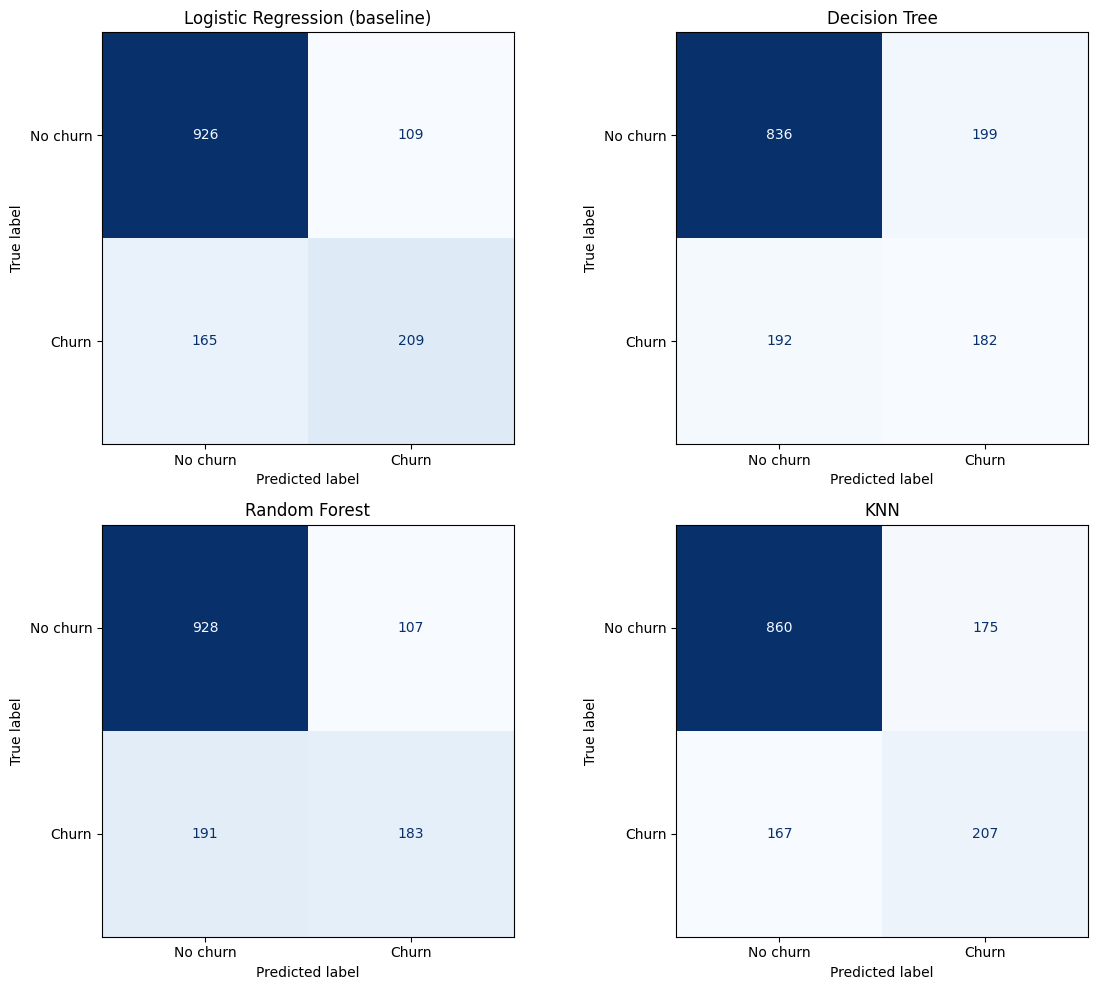

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, (name, y_pred) in zip(axes.ravel(), predictions.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=confusion_matrix(y_test, y_pred),
        display_labels=["No churn", "Churn"],
    ).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)

plt.tight_layout()
plt.show()